# Análisis Exploratorio de los Datos (EDA)

## Parte 1

### Cargar los datos

In [1]:
# Importaciones

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Cargamos el dataset
df = pd.read_excel("parteAccidentes.xlsx")

# Inspección inicial: tamaño, tipos de dato y nulos por columna
print("Filas x columnas:", df.shape, "\n")
df.info()
print("\nNulos por columna:")
print(df.isnull().sum())

df.head()

Filas x columnas: (49340, 19) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49340 entries, 0 to 49339
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   num_expediente        49340 non-null  object        
 1   fecha                 49340 non-null  datetime64[ns]
 2   hora                  49340 non-null  object        
 3   localizacion          49340 non-null  object        
 4   numero                49340 non-null  object        
 5   cod_distrito          49340 non-null  int64         
 6   distrito              49340 non-null  object        
 7   tipo_accidente        49335 non-null  object        
 8   estado_meteorológico  43424 non-null  object        
 9   tipo_vehiculo         48946 non-null  object        
 10  tipo_persona          49340 non-null  object        
 11  rango_edad            49340 non-null  object        
 12  sexo                  49340 non-null  obje

,num_expediente,fecha,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,cod_lesividad,lesividad,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,positiva_droga
0,2023S040280,2024-01-04,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión fronto-lateral,Lluvia débil,Motocicleta > 125cc,Conductor,De 55 a 59 años,Hombre,2.0,Ingreso inferior o igual a 24 horas,444913.056,4481427.179,N,NaN
1,2023S040280,2024-01-04,14:09:00,AVDA. NICETO ALCALA ZAMORA / AUTOV. M-11,3,16,HORTALEZA,Colisión fronto-lateral,Lluvia débil,Turismo,Conductor,De 55 a 59 años,Mujer,14.0,Sin asistencia sanitaria,444913.056,4481427.179,N,NaN
2,2023S040309,2024-02-15,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión fronto-lateral,Lluvia débil,Bicicleta,Conductor,De 25 a 29 años,Hombre,7.0,Asistencia sanitaria sólo en el lugar del acci...,440122.814,4475169.548,N,NaN
3,2023S040309,2024-02-15,14:05:00,CALL. TESORO / CALL. MINAS,18,1,CENTRO,Colisión fronto-lateral,Lluvia débil,Motocicleta hasta 125cc,Conductor,De 35 a 39 años,Hombre,14.0,Sin asistencia sanitaria,440122.814,4475169.548,N,NaN
4,2023S040310,2024-02-18,10:40:00,GTA. RUIZ JIMENEZ / CALL. SAN BERNARDO,3,7,CHAMBERÍ,Colisión lateral,Despejado,Turismo,Conductor,De 25 a 29 años,Hombre,NaN,NaN,440136.981,4475721.316,N,NaN


#### Descripción del dataset

El fichero recoge los **partes de accidentes de tráfico de Madrid durante 2024** (49.340 filas y 19 columnas). Resumen de las variables:

| Variable | Descripción | Nivel |
|---|---|---|
| `num_expediente` | Identificador del accidente. Agrupa a todas las personas implicadas en un mismo siniestro | Clave |
| `fecha`, `hora` | Momento del accidente | Accidente |
| `localizacion`, `numero`, `cod_distrito`, `distrito` | Dónde ocurrió | Accidente |
| `coordenada_x_utm`, `coordenada_y_utm` | Posición (UTM) | Accidente |
| `tipo_accidente` | Colisión fronto-lateral, alcance, atropello... | Accidente |
| `estado_meteorológico` | Despejado, nublado, lluvia... | Accidente |
| `tipo_vehiculo` | Vehículo de la persona | Persona |
| `tipo_persona`, `rango_edad`, `sexo` | Conductor / pasajero / peatón, tramo de edad y sexo | Persona |
| `cod_lesividad`, `lesividad` | Gravedad de las lesiones de esa persona (14 = sin asistencia, 3 = ingreso > 24 h, 4 = fallecido...) | Persona |
| `positiva_alcohol`, `positiva_droga` | Resultado de la prueba de alcohol / droga de esa persona | Persona |

`positiva_droga` solo tiene 203 valores no nulos (el 99,6 % está vacío), `cod_lesividad` y `lesividad` tienen 21.996 nulos y `estado_meteorológico` 5.916.

In [2]:
# Granularidad: ¿qué representa una fila?
n_personas = len(df)
n_accidentes = df["num_expediente"].nunique()

print(f"Filas (personas implicadas): {n_personas}")
print(f"Accidentes distintos (num_expediente únicos): {n_accidentes}")
print(f"Media de personas implicadas por accidente: {n_personas / n_accidentes:.2f}\n")

personas_por_accidente = df.groupby("num_expediente").size()
print(personas_por_accidente.describe(), "\n")
print(
    f"% de accidentes con una sola persona implicada: {(personas_por_accidente == 1).mean() * 100:.1f}%"
)
print(
    f"% de filas que pertenecen a accidentes con 3 o más personas: {df['num_expediente'].map(personas_por_accidente).ge(3).mean() * 100:.1f}%\n"
)

# Comprobamos que las variables del SINIESTRO no cambian dentro de un mismo num_expediente
# (si salen True, se pueden usar a nivel accidente tomando la primera fila de cada expediente)
vars_accidente = [
    "fecha",
    "hora",
    "tipo_accidente",
    "estado_meteorológico",
    "distrito",
    "coordenada_x_utm",
    "coordenada_y_utm",
]
print("¿Constantes dentro de cada accidente?")
print((df.groupby("num_expediente")[vars_accidente].nunique(dropna=False) <= 1).all())

Filas (personas implicadas): 49340
Accidentes distintos (num_expediente únicos): 20698
Media de personas implicadas por accidente: 2.38

count    20698.000000
mean         2.383805
std          1.179356
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max         22.000000
dtype: float64 

% de accidentes con una sola persona implicada: 14.7%
% de filas que pertenecen a accidentes con 3 o más personas: 47.7%

¿Constantes dentro de cada accidente?
fecha                   True
hora                    True
tipo_accidente          True
estado_meteorológico    True
distrito                True
coordenada_x_utm        True
coordenada_y_utm        True
dtype: bool


#### ¡Ojo! Granularidad del dataset: una fila NO es un accidente

El dataset **no está a nivel accidente, sino a nivel accidentado**: cada fila es **una persona implicada** en un siniestro. Hay 49.340 personas repartidas en solo **20.698 accidentes** (2,38 personas por accidente de media, con un máximo de 22). El 85 % de los accidentes involucra a más de una persona y casi la mitad de las filas (47,7 %) pertenecen a accidentes con 3 o más implicados.

Además, las variables propias del siniestro (fecha, hora, tipo de accidente, meteorología, distrito y coordenadas) valen **lo mismo para todas las filas de un mismo `num_expediente`**, mientras que la lesividad, la edad, el sexo, el vehículo y el alcohol son propias de cada persona.

Consecuencia y forma de trabajar a partir de aquí:

- **Para contar accidentes** (cuántos hubo, de qué tipo, en qué franja, dónde) se usa `df_acc`, con **una fila por `num_expediente`**. Si se contaran filas, un accidente con diez víctimas pesaría diez veces más que uno con una sola persona.
- **Para hablar de personas** (lesividad, edad, sexo, alcohol) se usa `df`, a nivel persona.
- **El modelo de la Parte 2** se mantiene a nivel persona, porque predice si *esa persona* dio positivo en alcohol.
- En cada gráfico se indica a qué nivel está calculado. Por eso se conserva `num_expediente` en la limpieza (antes se eliminaba).

### Limpieza y tratamiento de valores nulos

In [3]:
# Limpieza del dataset

# OJO: num_expediente SE CONSERVA, es la clave que agrupa a las personas de un mismo accidente.
df = df.drop(
    columns=["positiva_droga"]
)  # positiva droga es al 99% nulos damos por no valida esa columna

# Borramos las filas con datos del siniestro que no puedo inventar (son constantes por accidente, así que se pierde el accidente entero)
df = df.dropna(subset=["tipo_accidente", "coordenada_x_utm", "coordenada_y_utm"])

# positiva_alcohol (167 nulos) NO se rellena: se deja a NaN y se excluye solo en los análisis del alcohol y en el modelo

df["estado_meteorológico"] = df["estado_meteorológico"].fillna(
    "Desconocido"
)  # No puedo inventar un estado metereologico ni meterle una media en base a los demas
df["estado_meteorológico"] = df["estado_meteorológico"].replace(
    {"Se desconoce": "Desconocido", "LLuvia intensa": "Lluvia intensa"}
)  # unifico etiquetas (y corrijo una errata)
df["tipo_vehiculo"] = df["tipo_vehiculo"].fillna(
    "Desconocido"
)  # No puedo inventar un tipo de vehiculo

df["lesividad"] = df["lesividad"].fillna(
    "Sin asistencia sanitaria"
)  # Lesividad en blanco = Sin asistencia (referencia el doc de la policia)
df["cod_lesividad"] = df["cod_lesividad"].fillna(
    14
)  # Lesividad en blanco = Cod 14 (referencia el doc de la policia)
df["cod_lesividad"] = df["cod_lesividad"].astype(int)

print(
    f"Tras la limpieza: {len(df)} personas en {df['num_expediente'].nunique()} accidentes"
)

Tras la limpieza: 49330 personas en 20692 accidentes


#### Transformación de variables

Se crean las variables necesarias **sin utilizar nunca la variable objetivo (el alcohol)** para construirlas:

- La **franja horaria** pasa a ser una categoría con nombre (`Madrugada` 0-5 h, `Mañana` 6-11 h, `Tarde` 12-19 h, `Noche` 20-23 h) en lugar de los números arbitrarios que se usaban antes (que además daban el valor más alto a la madrugada).
- Las variables categóricas (tipo de accidente, edad, sexo, vehículo...) **ya no se sustituyen por la tasa de alcohol de su categoría**. Esa codificación metía el objetivo dentro de las predictoras (fuga de datos) y contaminaba el mapa de calor y el modelo. Ahora, para el modelo, se usa codificación binaria (one-hot) y, para los análisis, las categorías originales.
- El **sexo desconocido** (10,6 % de las filas) ya no se convierte en "Mujer": es su propia categoría.
- La **lesividad** mantiene su escala ordinal (ileso < leve < grave < fallecido) y se añade `grave` (ingreso > 24 h o fallecido), que es la definición de la pregunta de negocio. A nivel accidente, `grave` vale 1 si **alguna** de las personas implicadas es grave.

In [4]:
# TRANSFORMACION DE VARIABLES (sin usar nunca la variable objetivo)

# Columna dia del accidente
df["dia_semana"] = df["fecha"].dt.day_of_week
df["tipo_dia"] = np.where(df["dia_semana"] >= 5, "Fin de Semana", "Lunes a Viernes")

# Columna franja horaria: categoría ordenada con nombre, sin números inventados
df["hora_num"] = pd.to_datetime(
    df["hora"].astype(str), format="%H:%M:%S", errors="coerce"
).dt.hour  # errors='coerce' por si hay algún dato mal escrito
df["franja"] = pd.cut(
    df["hora_num"],
    bins=[-1, 5, 11, 19, 23],
    labels=["Madrugada", "Mañana", "Tarde", "Noche"],
)  # 0-5, 6-11, 12-19, 20-23

# Columna positivo alcohol, conversion de str a int (los nulos se quedan como NaN)
df["positiva_alcohol"] = df["positiva_alcohol"].map({"S": 1, "N": 0})


# Columna Cod_Lesividad
# Escala ordinal que respeta el orden real (sino se compararia el 14 (Ileso) con un 4 (fallecimiento))
def escalar_gravedad(codigo):
    if codigo == 14:
        return 0.0  # Ileso
    elif codigo in [1, 2, 5, 6, 7]:
        return 0.33  # Leve
    elif codigo == 3:
        return 0.66  # Grave (ingreso > 24 h)
    elif codigo == 4:
        return 1.0  # Fallecido
    else:
        return np.nan  # 77 = se desconoce


df["gravedad_num"] = df["cod_lesividad"].apply(escalar_gravedad)
niveles = {0.0: "Ileso", 0.33: "Leve", 0.66: "Grave", 1.0: "Fallecido"}
df["nivel_lesividad"] = pd.Categorical(
    df["gravedad_num"].map(niveles), categories=list(niveles.values()), ordered=True
)

# Persona GRAVE = ingreso superior a 24 horas o fallecido (la definición de la pregunta de negocio)
df["grave"] = df["cod_lesividad"].isin([3, 4]).astype(int)

# Columna tipo de vehiculo: agrupo los menos frecuentes para tener pocas categorias manejables
top_vehiculos = df["tipo_vehiculo"].value_counts().head(8).index
df["grupo_vehiculo"] = df["tipo_vehiculo"].where(
    df["tipo_vehiculo"].isin(top_vehiculos), "Otros"
)

# Vista a nivel ACCIDENTE: una fila por num_expediente
df_acc = (
    df.groupby("num_expediente")
    .agg(
        fecha=("fecha", "first"),
        dia_semana=("dia_semana", "first"),
        tipo_dia=("tipo_dia", "first"),
        hora_num=("hora_num", "first"),
        franja=("franja", "first"),
        tipo_accidente=("tipo_accidente", "first"),
        estado_meteorológico=("estado_meteorológico", "first"),
        distrito=("distrito", "first"),
        coordenada_x_utm=("coordenada_x_utm", "first"),
        coordenada_y_utm=("coordenada_y_utm", "first"),
        n_personas=("num_expediente", "size"),
        gravedad_max=(
            "gravedad_num",
            "max",
        ),  # la víctima más afectada define la gravedad del siniestro
        grave=(
            "grave",
            "max",
        ),  # accidente grave = al menos una persona grave o fallecida
    )
    .reset_index()
)

print(f"df (nivel persona):   {df.shape}")
print(f"df_acc (nivel accidente): {df_acc.shape}")
df_acc.head()

df (nivel persona):   (49330, 26)
df_acc (nivel accidente): (20692, 14)


,num_expediente,fecha,dia_semana,tipo_dia,hora_num,franja,tipo_accidente,estado_meteorológico,distrito,coordenada_x_utm,coordenada_y_utm,n_personas,gravedad_max,grave
0,2023S040280,2024-01-04,3,Lunes a Viernes,14,Tarde,Colisión fronto-lateral,Lluvia débil,HORTALEZA,444913.056,4481427.179,2,0.33,0
1,2023S040309,2024-02-15,3,Lunes a Viernes,14,Tarde,Colisión fronto-lateral,Lluvia débil,CENTRO,440122.814,4475169.548,2,0.33,0
2,2023S040310,2024-02-18,6,Fin de Semana,10,Mañana,Colisión lateral,Despejado,CHAMBERÍ,440136.981,4475721.316,2,0.00,0
3,2023S040312,2024-02-25,6,Fin de Semana,17,Tarde,Colisión lateral,Despejado,TETUÁN,440708.685,4480101.999,2,0.00,0
4,2023S040316,2024-03-07,3,Lunes a Viernes,14,Tarde,Alcance,Lluvia débil,LATINA,433983.046,4468472.755,2,0.00,0


### Exploración univariante y bivariante

#### Análisis univariante

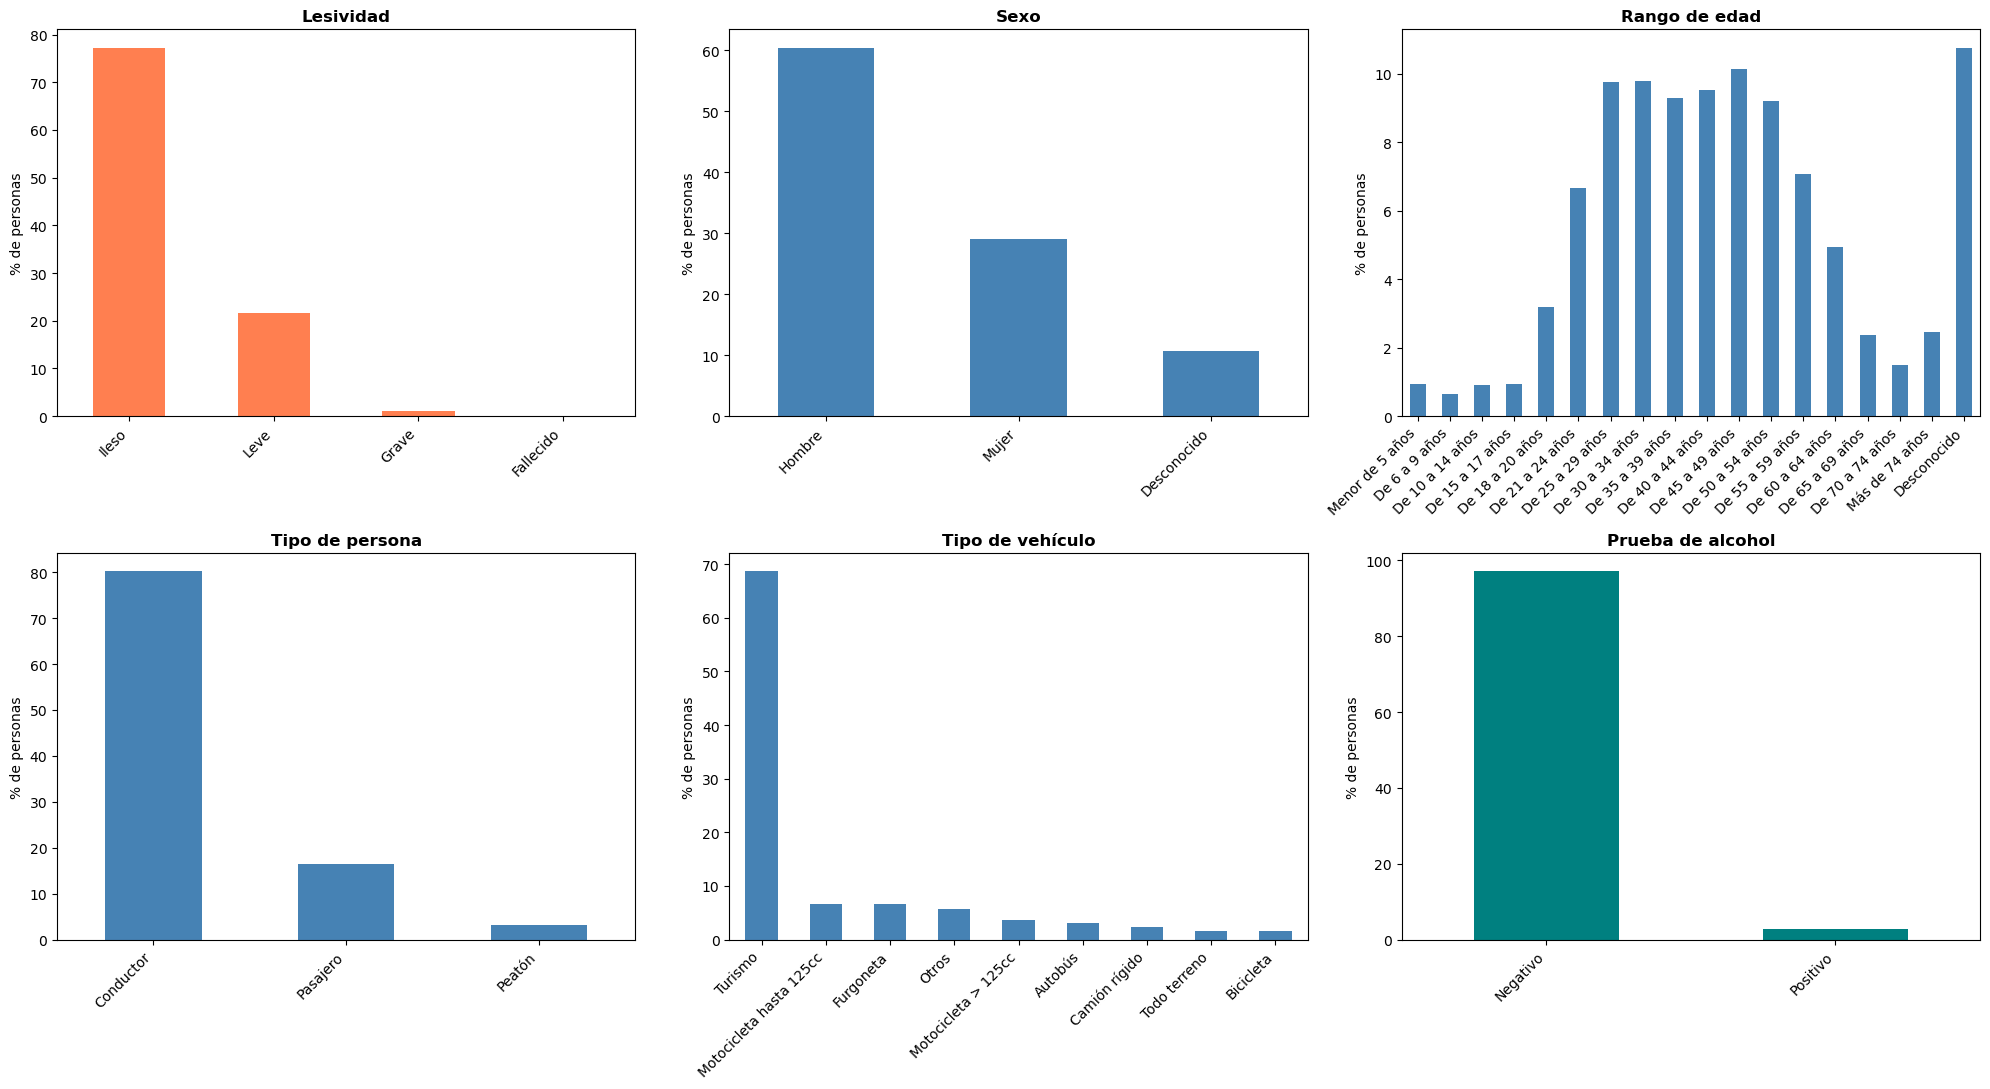

Lesividad (% personas):
 nivel_lesividad
Ileso        77.25
Leve         21.54
Grave         1.15
Fallecido     0.06

Positivos en alcohol: 2.91% de las 49163 personas con prueba registrada


In [5]:
# Univariante - variables a nivel PERSONA (cada fila de df es una persona implicada)

orden_edad = [
    "Menor de 5 años",
    "De 6 a 9 años",
    "De 10 a 14 años",
    "De 15 a 17 años",
    "De 18 a 20 años",
    "De 21 a 24 años",
    "De 25 a 29 años",
    "De 30 a 34 años",
    "De 35 a 39 años",
    "De 40 a 44 años",
    "De 45 a 49 años",
    "De 50 a 54 años",
    "De 55 a 59 años",
    "De 60 a 64 años",
    "De 65 a 69 años",
    "De 70 a 74 años",
    "Más de 74 años",
    "Desconocido",
]


def distribucion(serie, ax, titulo, orden=None, color="steelblue"):
    """Barras con el % de cada categoría."""
    pct = serie.value_counts(normalize=True) * 100
    if orden is not None:
        pct = pct.reindex(orden)
    pct.plot(kind="bar", ax=ax, color=color)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("% de personas")
    ax.tick_params(axis="x", rotation=45)
    for lab in ax.get_xticklabels():
        lab.set_ha("right")


fig, axes = plt.subplots(2, 3, figsize=(20, 11))
distribucion(df["nivel_lesividad"], axes[0, 0], "Lesividad", color="coral")
distribucion(df["sexo"], axes[0, 1], "Sexo")
distribucion(df["rango_edad"], axes[0, 2], "Rango de edad", orden=orden_edad)
distribucion(df["tipo_persona"], axes[1, 0], "Tipo de persona")
distribucion(df["grupo_vehiculo"], axes[1, 1], "Tipo de vehículo")
distribucion(
    df["positiva_alcohol"].map({0: "Negativo", 1: "Positivo"}),
    axes[1, 2],
    "Prueba de alcohol",
    color="teal",
)
plt.tight_layout()
plt.show()

print(
    "Lesividad (% personas):\n",
    (df["nivel_lesividad"].value_counts(normalize=True) * 100).round(2).to_string(),
)
print(
    f"\nPositivos en alcohol: {df['positiva_alcohol'].mean() * 100:.2f}% de las {df['positiva_alcohol'].notna().sum()} personas con prueba registrada"
)

**Interpretación (nivel persona, 49.330 personas):**

- **Lesividad:** la gran mayoría sale ilesa (77,3 %) o con lesiones leves (21,5 %). Los casos graves (ingreso > 24 h) son el 1,15 % y los fallecidos el 0,06 %. La gravedad es un suceso poco frecuente, lo que habrá que tener presente al comparar tasas.
- **Sexo:** 60,4 % hombres, 29,0 % mujeres y 10,6 % desconocido.
- **Edad:** la mayor parte de los implicados tiene entre 25 y 54 años; los menores de 18 y los mayores de 65 son minoritarios. El 10,8 % tiene la edad desconocida.
- **Tipo de persona:** el 80,2 % son conductores, el 16,5 % pasajeros y solo el 3,3 % peatones.
- **Vehículo:** el turismo domina claramente (68,7 %), seguido de motocicletas hasta 125cc (6,7 %) y furgonetas (6,6 %).
- **Alcohol:** solo el **2,91 %** de las personas con prueba registrada dio positivo. Es un objetivo muy desbalanceado, lo que condiciona el modelo de la Parte 2.

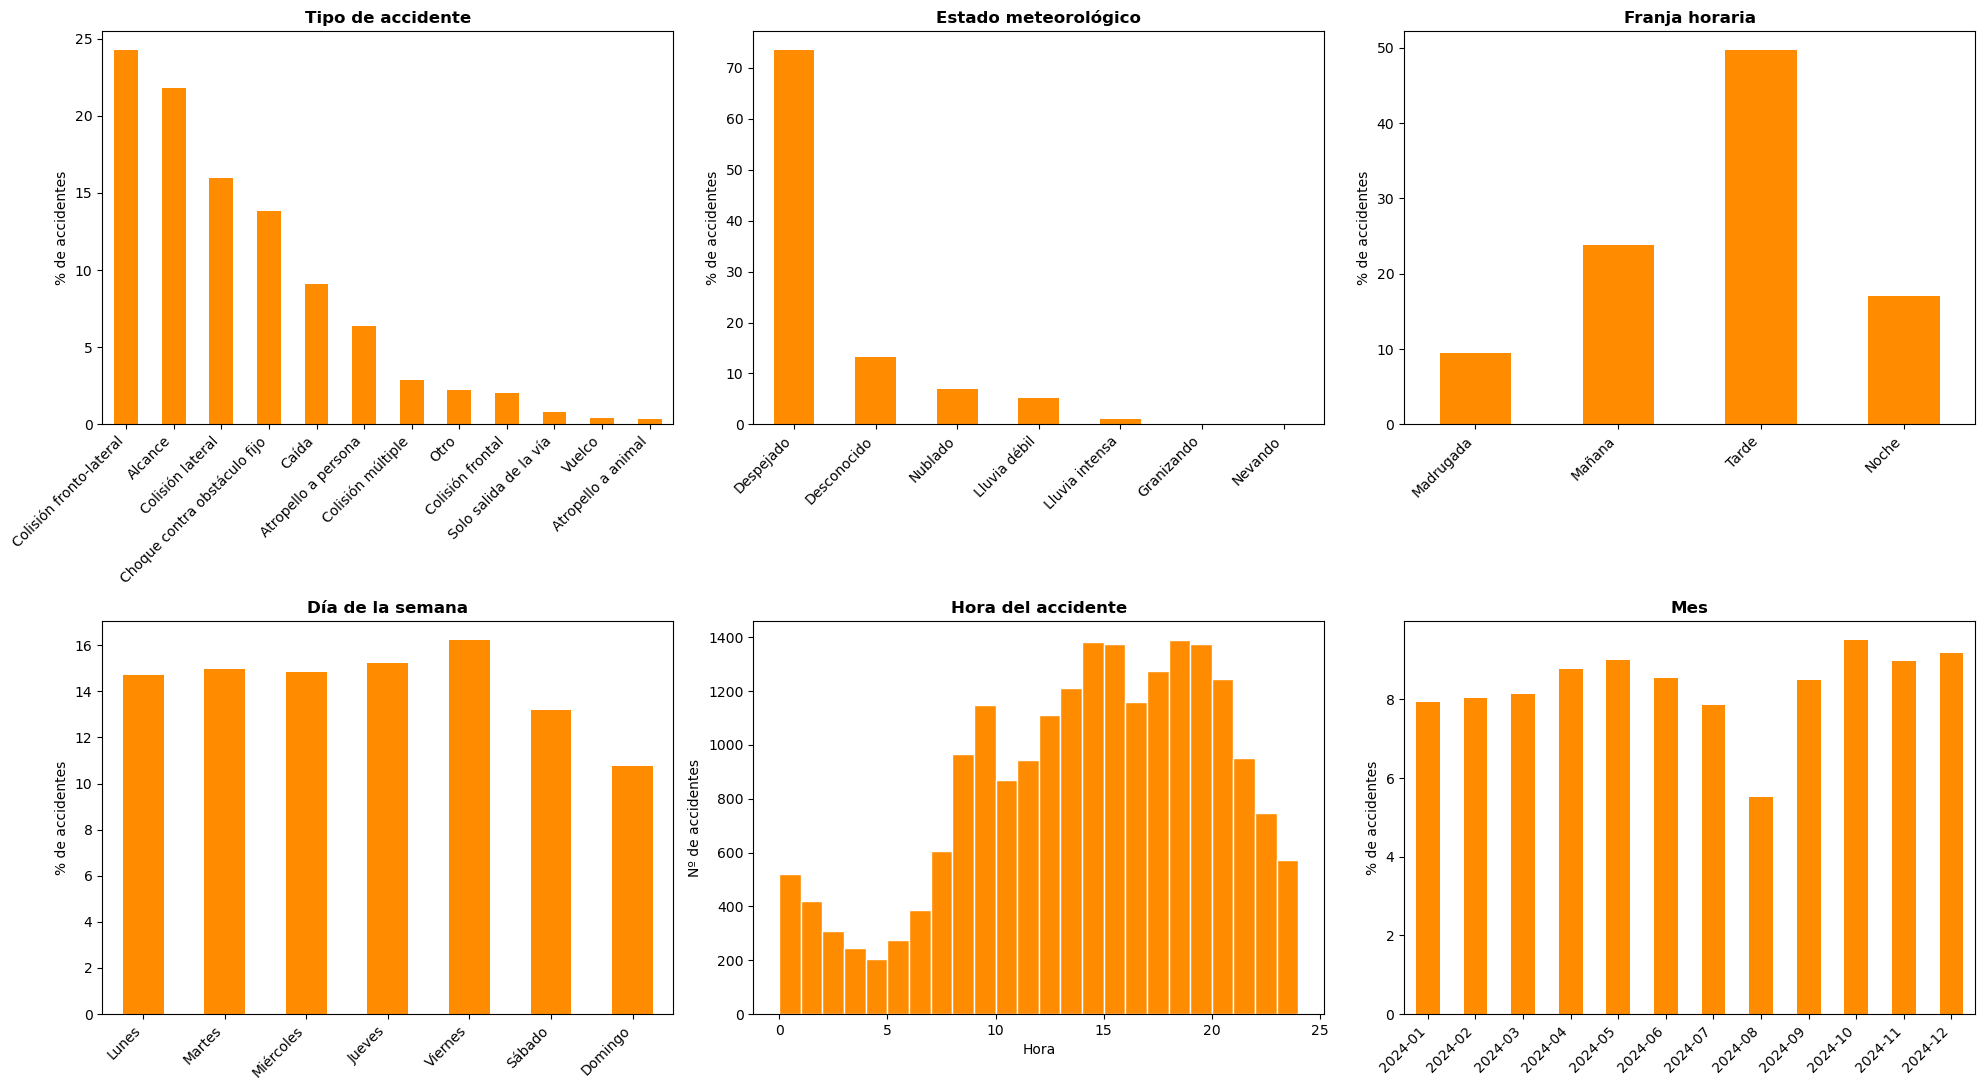

Periodo cubierto: 2024-01-01 -> 2024-12-31
% de accidentes graves (ingreso > 24 h o fallecido): 2.67%
tipo_accidente
Colisión fronto-lateral         24.3
Alcance                         21.8
Colisión lateral                15.9
Choque contra obstáculo fijo    13.8
Caída                            9.1
Atropello a persona              6.4
Colisión múltiple                2.9
Otro                             2.3
Colisión frontal                 2.0
Solo salida de la vía            0.8
Vuelco                           0.4
Atropello a animal               0.3
estado_meteorológico
Despejado         15206
Desconocido        2749
Nublado            1449
Lluvia débil       1064
Lluvia intensa      221
Granizando            2
Nevando               1


In [6]:
# Univariante - variables a nivel ACCIDENTE (una fila por num_expediente en df_acc)

nombres_dias = [
    "Lunes",
    "Martes",
    "Miércoles",
    "Jueves",
    "Viernes",
    "Sábado",
    "Domingo",
]


def distribucion_acc(serie, ax, titulo, orden=None, color="steelblue"):
    pct = serie.value_counts(normalize=True) * 100
    if orden is not None:
        pct = pct.reindex(orden)
    pct.plot(kind="bar", ax=ax, color=color)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("% de accidentes")
    ax.tick_params(axis="x", rotation=45)
    for lab in ax.get_xticklabels():
        lab.set_ha("right")


fig, axes = plt.subplots(2, 3, figsize=(20, 11))
distribucion_acc(
    df_acc["tipo_accidente"], axes[0, 0], "Tipo de accidente", color="darkorange"
)
distribucion_acc(
    df_acc["estado_meteorológico"],
    axes[0, 1],
    "Estado meteorológico",
    color="darkorange",
)
distribucion_acc(
    df_acc["franja"],
    axes[0, 2],
    "Franja horaria",
    orden=["Madrugada", "Mañana", "Tarde", "Noche"],
    color="darkorange",
)
distribucion_acc(
    df_acc["dia_semana"].map(dict(enumerate(nombres_dias))),
    axes[1, 0],
    "Día de la semana",
    orden=nombres_dias,
    color="darkorange",
)
df_acc["hora_num"].plot(
    kind="hist", bins=range(0, 25), ax=axes[1, 1], color="darkorange", edgecolor="white"
)
axes[1, 1].set_title("Hora del accidente", fontweight="bold")
axes[1, 1].set_xlabel("Hora")
axes[1, 1].set_ylabel("Nº de accidentes")
distribucion_acc(
    df_acc["fecha"].dt.to_period("M").astype(str),
    axes[1, 2],
    "Mes",
    orden=sorted(df_acc["fecha"].dt.to_period("M").astype(str).unique()),
    color="darkorange",
)
plt.tight_layout()
plt.show()

print(
    "Periodo cubierto:",
    df_acc["fecha"].min().date(),
    "->",
    df_acc["fecha"].max().date(),
)
print(
    f"% de accidentes graves (ingreso > 24 h o fallecido): {df_acc['grave'].mean() * 100:.2f}%"
)
print(
    (df_acc["tipo_accidente"].value_counts(normalize=True) * 100).round(1).to_string()
)
print((df_acc["estado_meteorológico"].value_counts()).to_string())

**Interpretación (nivel accidente, 20.692 accidentes de 2024):**

- **Tipo de accidente:** colisión fronto-lateral (24,3 %), alcance (21,8 %), colisión lateral (15,9 %) y choque contra obstáculo fijo (13,8 %) suman tres cuartas partes de los siniestros. Al contar accidentes en vez de personas el orden de los primeros tipos se mantiene, pero cambian algunos pesos: las caídas pasan del 5,4 % de las filas al 9,1 % de los accidentes (suelen ser de una sola persona) y la colisión múltiple del 5,1 % al 2,9 % (implica a muchas personas). Esa es la distorsión que producía contar filas.
- **Meteorología:** el 73,5 % ocurre con tiempo despejado, y un 13,3 % tiene el estado "Desconocido". La lluvia (débil + intensa) es el 6,2 %; granizo y nieve son anecdóticos (2 y 1 accidentes en todo el año).
- **Franja horaria:** la tarde (12-20 h) concentra el 49,7 % de los accidentes, seguida de la mañana (23,8 %), la noche (17,0 %) y la madrugada (9,5 %). La hora muestra un pico matinal a las 9 h y una meseta de 13 h a 20 h con picos alrededor de las 14 y las 18 h.
- **Día de la semana:** de lunes a viernes hay entre el 14,7 % y el 16,2 % de los accidentes cada día (el viernes es el máximo), el sábado baja al 13,2 % y el domingo al 10,8 %.
- **Mes:** hay algo más de accidentes entre abril y junio y entre octubre y diciembre; **agosto** es el mes con menos (5,5 %), coherente con las vacaciones y la menor circulación.
- **Gravedad:** el **2,67 %** de los accidentes es grave (alguna persona con ingreso > 24 h o fallecida).

#### Análisis bivariante

Días naturales en el periodo: {'Lunes a Viernes': 262, 'Fin de Semana': 104}


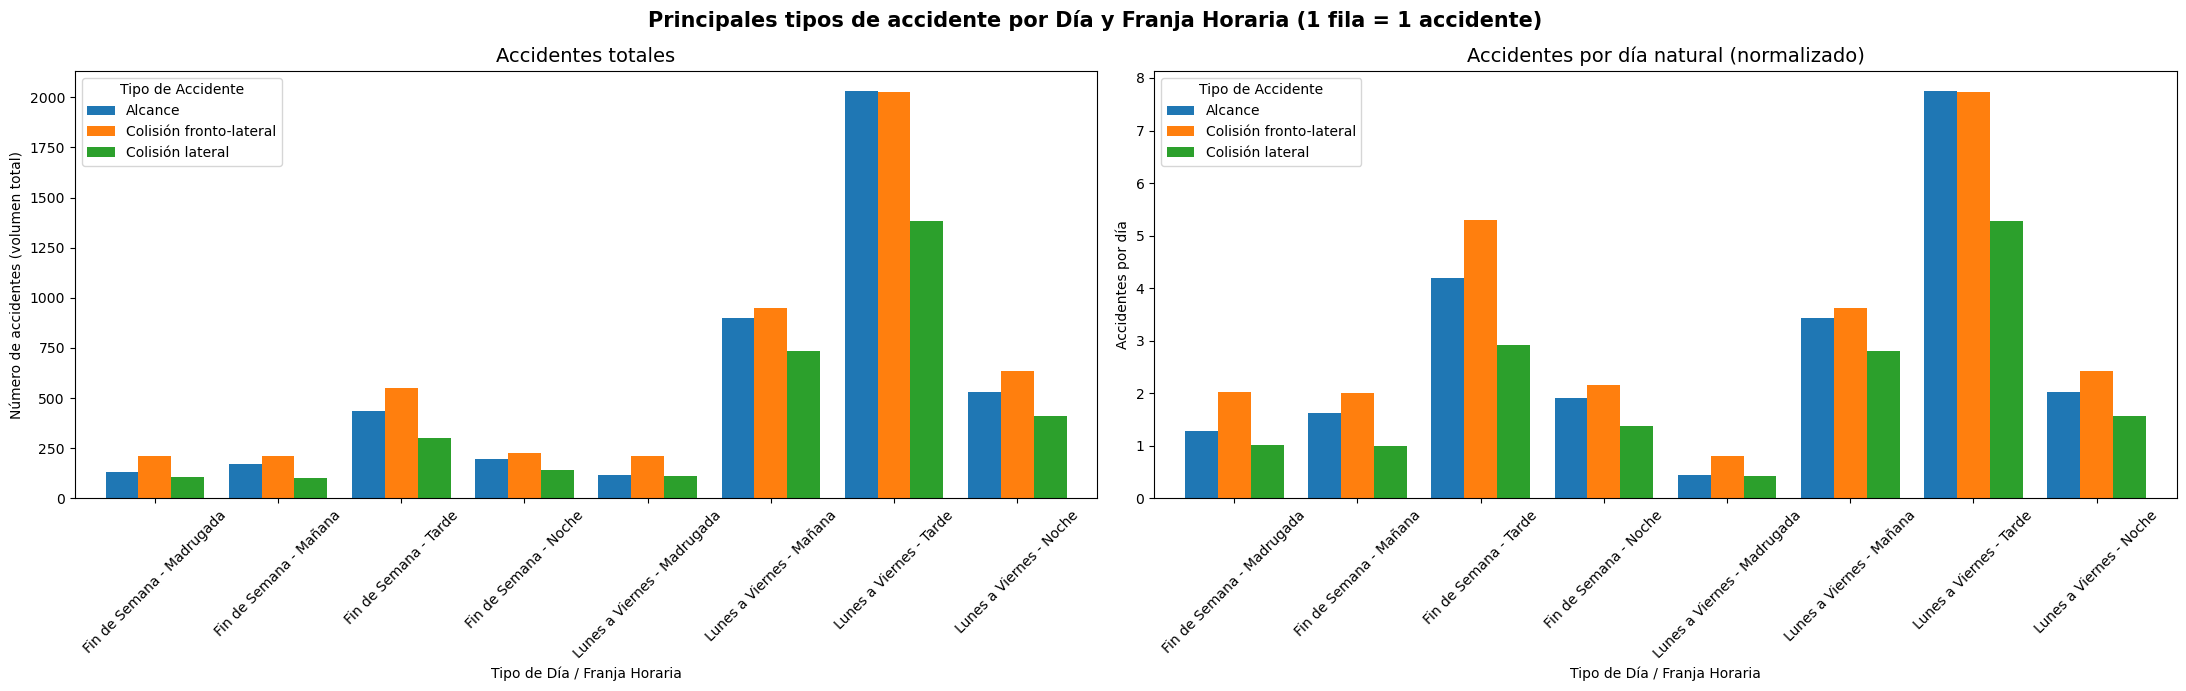

Accidentes por día natural (todos los tipos):
franja           Madrugada  Mañana  Tarde  Noche
Fin de Semana         9.26    9.18  19.96   9.29
Lunes a Viernes       3.86   15.13  31.32   9.73

Fin de semana / Laborable (veces):
franja
Madrugada    2.40
Mañana       0.61
Tarde        0.64
Noche        0.95


In [7]:
# Busqueda de relaciones (nivel ACCIDENTE)

# ¿Existe relación entre la hora y el tipo de accidente? Para tomar esta decision considero necesario saber si fue de lunes, miercoles, sabado, la franja horaria donde ocurrio el accidente, y el tipo de accidente.

top_accidentes = (
    df_acc["tipo_accidente"].value_counts().head(3).index
)  # En este caso voy a coger los 3 accidentes mas importantes para que no quede una grafica muy extensa
df_top = df_acc[df_acc["tipo_accidente"].isin(top_accidentes)]

# Tabla dinámica: accidentes (no personas) por tipo de día, franja y tipo de accidente
tabla_3_variables = pd.crosstab(
    [df_top["tipo_dia"], df_top["franja"]], df_top["tipo_accidente"]
)

# Normalizamos por los días naturales que hay de cada tipo en el periodo (si no, 5 laborables pesan más que 2 de fin de semana)
rango = pd.date_range(
    df_acc["fecha"].min().normalize(), df_acc["fecha"].max().normalize()
)
dias_por_tipo = pd.Series(
    np.where(rango.day_of_week >= 5, "Fin de Semana", "Lunes a Viernes")
).value_counts()
print("Días naturales en el periodo:", dias_por_tipo.to_dict())

tabla_por_dia = tabla_3_variables.div(
    tabla_3_variables.index.get_level_values(0).map(dias_por_tipo).values, axis=0
)

etiquetas = [f"{dia} - {franja}" for dia, franja in tabla_3_variables.index]
fig, axes = plt.subplots(1, 2, figsize=(22, 7))
for ax, tabla, titulo, ylab in [
    (
        axes[0],
        tabla_3_variables,
        "Accidentes totales",
        "Número de accidentes (volumen total)",
    ),
    (
        axes[1],
        tabla_por_dia,
        "Accidentes por día natural (normalizado)",
        "Accidentes por día",
    ),
]:
    t = tabla.copy()
    t.index = etiquetas
    t.plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(titulo, fontsize=14)
    ax.set_ylabel(ylab)
    ax.set_xlabel("Tipo de Día / Franja Horaria")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Tipo de Accidente")
plt.suptitle(
    "Principales tipos de accidente por Día y Franja Horaria (1 fila = 1 accidente)",
    fontsize=15,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Accidentes por día natural, todos los tipos, y cuánto se multiplica en fin de semana
todos = pd.crosstab(df_acc["tipo_dia"], df_acc["franja"]).div(dias_por_tipo, axis=0)
print("Accidentes por día natural (todos los tipos):")
print(todos.round(2).to_string())
print("\nFin de semana / Laborable (veces):")
print((todos.loc["Fin de Semana"] / todos.loc["Lunes a Viernes"]).round(2).to_string())

#### Tipos de accidente por día y franja (nivel accidente)

El gráfico de la izquierda muestra el número total de accidentes y el de la derecha los **accidentes por día natural**. Como el periodo tiene 262 días laborables y 104 de fin de semana, comparar los totales favorece a los laborables; al dividir por los días de cada tipo, la comparación es justa.

- **Lunes a viernes** concentra el mayor volumen en la **tarde**: 31,3 accidentes por día. En las horas punta la saturación de las vías, las prisas y el cansancio de la jornada explican el volumen. Los dos tipos dominantes aquí son prácticamente equivalentes (alcance 7,75 y colisión fronto-lateral 7,74 accidentes por día), por lo que no se puede decir que los alcances dominen de forma clara.
- **Fines de semana:** la colisión fronto-lateral supera al alcance en todas las franjas (por ejemplo, 5,30 frente a 4,20 por día en la tarde, o 2,03 frente a 1,29 en la madrugada).
- **¿Cuánto más ocurre en fin de semana?** Por día natural, la **madrugada** de fin de semana tiene **2,40 veces** más accidentes que la de un día laborable (9,26 frente a 3,86), es decir, un **+140 %**. En la noche el nivel es parecido (0,95×) y en la mañana y en la tarde de fin de semana hay menos accidentes por día que en un laborable (0,61× y 0,64×). El efecto de ocio nocturno es, por tanto, exclusivo de la madrugada y no de toda la tarde-noche.

Este análisis se corrige respecto a la versión anterior: se contaban personas (no accidentes) y se hablaba de un "+250 %" que no se sostiene al contar siniestros.

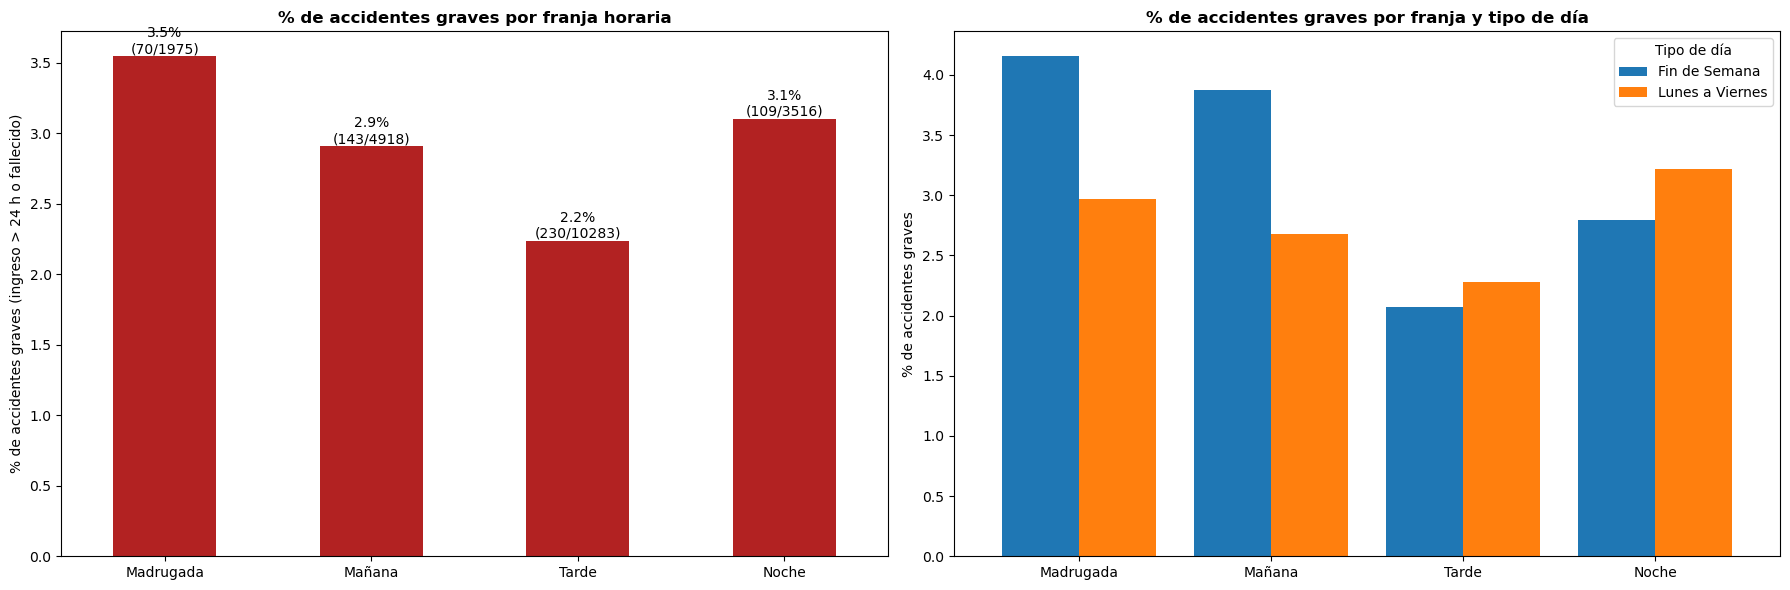

           tasa  graves  accidentes
franja                             
Madrugada  3.54      70        1975
Mañana     2.91     143        4918
Tarde      2.24     230       10283
Noche      3.10     109        3516

                           tasa  graves  accidentes
tipo_dia        franja                             
Fin de Semana   Madrugada  4.15      40         963
                Mañana     3.87      37         955
                Tarde      2.07      43        2076
                Noche      2.80      27         966
Lunes a Viernes Madrugada  2.96      30        1012
                Mañana     2.67     106        3963
                Tarde      2.28     187        8207
                Noche      3.22      82        2550


In [8]:
# Proporción de accidentes GRAVES por franja horaria (evidencia directa para la pregunta de negocio)

orden_franja = ["Madrugada", "Mañana", "Tarde", "Noche"]
tasa_franja = (
    df_acc.groupby("franja", observed=True)["grave"]
    .agg(tasa="mean", graves="sum", accidentes="size")
    .reindex(orden_franja)
)
tasa_franja_dia = df_acc.groupby(["tipo_dia", "franja"], observed=True)["grave"].agg(
    tasa="mean", graves="sum", accidentes="size"
)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

(tasa_franja["tasa"] * 100).plot(kind="bar", ax=axes[0], color="firebrick")
axes[0].set_title("% de accidentes graves por franja horaria", fontweight="bold")
axes[0].set_ylabel("% de accidentes graves (ingreso > 24 h o fallecido)")
axes[0].set_xlabel("")
for i, (t, g, n) in enumerate(
    tasa_franja[["tasa", "graves", "accidentes"]].itertuples(index=False)
):
    axes[0].text(
        i, t * 100, f"{t * 100:.1f}%\n({int(g)}/{int(n)})", ha="center", va="bottom"
    )
axes[0].tick_params(axis="x", rotation=0)

pivot = (tasa_franja_dia["tasa"] * 100).unstack("tipo_dia").reindex(orden_franja)
pivot.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_title("% de accidentes graves por franja y tipo de día", fontweight="bold")
axes[1].set_ylabel("% de accidentes graves")
axes[1].set_xlabel("")
axes[1].legend(title="Tipo de día")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print(tasa_franja.assign(tasa=lambda d: (d["tasa"] * 100).round(2)).to_string())
print()
print(tasa_franja_dia.assign(tasa=lambda d: (d["tasa"] * 100).round(2)).to_string())

#### Proporción de accidentes graves por franja horaria

Este gráfico responde de forma directa a la pregunta de negocio: de todos los accidentes de cada franja, qué porcentaje es grave (ingreso > 24 h o fallecido).

- **Madrugada: 3,54 %** (70 de 1.975 accidentes), la tasa más alta, seguida de la **noche (3,10 %)**, la mañana (2,91 %) y, en último lugar, la **tarde (2,24 %)**. Estas diferencias son estadísticamente significativas (test chi-cuadrado, p < 0,001) aunque las tasas absolutas son pequeñas.
- La **tarde es la franja con más accidentes graves en número absoluto** (230), pero simplemente porque es donde hay más accidentes; en proporción es la menos grave.
- Por tipo de día, los extremos son la **madrugada de fin de semana (4,15 %)** y la **mañana de fin de semana (3,87 %)** (que recoge las primeras horas tras la noche), frente al 2,07 % de la tarde de fin de semana y al 2,3 % de la tarde de diario.
- Los grupos de fin de semana son pequeños (27-43 accidentes graves por grupo), por lo que estas diferencias hay que leerlas con cautela.

Con esto se corrige una conclusión previa: la gravedad no se concentra en la tarde-noche de fin de semana, sino de **madrugada** (y, en menor medida, en la noche y primeras horas de la mañana).

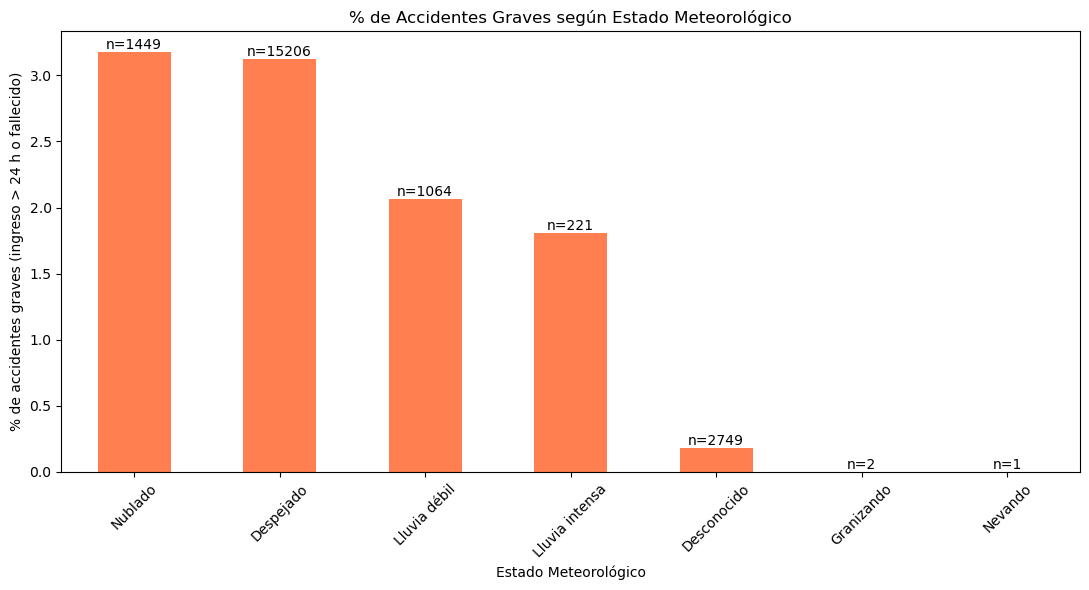

                      tasa  graves  accidentes
estado_meteorológico                          
Nublado               3.17      46        1449
Despejado             3.12     475       15206
Lluvia débil          2.07      22        1064
Lluvia intensa        1.81       4         221
Desconocido           0.18       5        2749
Granizando            0.00       0           2
Nevando               0.00       0           1

% de accidentes graves por tipo de accidente:
                               tasa  graves  accidentes
tipo_accidente                                         
Atropello a persona           12.46     164        1316
Vuelco                         4.71       4          85
Caída                          4.29      81        1887
Colisión fronto-lateral        3.29     165        5019
Colisión frontal               2.64      11         417
Solo salida de la vía          2.34       4         171
Colisión múltiple              1.35       8         594
Choque contra obstáculo fi

In [9]:
# ¿Existe relación entre el clima y la lesividad? (nivel ACCIDENTE)

tabla_clima = (
    df_acc.groupby("estado_meteorológico")["grave"]
    .agg(tasa="mean", graves="sum", accidentes="size")
    .sort_values("tasa", ascending=False)
)

ax = (tabla_clima["tasa"] * 100).plot(kind="bar", figsize=(11, 6), color="coral")
for i, (t, g, n) in enumerate(
    tabla_clima[["tasa", "graves", "accidentes"]].itertuples(index=False)
):
    ax.text(i, t * 100, f"n={int(n)}", ha="center", va="bottom")

plt.title("% de Accidentes Graves según Estado Meteorológico")
plt.ylabel("% de accidentes graves (ingreso > 24 h o fallecido)")
plt.xlabel("Estado Meteorológico")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print(tabla_clima.assign(tasa=lambda d: (d["tasa"] * 100).round(2)).to_string())

# Tasa de graves por tipo de accidente (condición que influye en la gravedad)
print("\n% de accidentes graves por tipo de accidente:")
print(
    df_acc.groupby("tipo_accidente")["grave"]
    .agg(tasa="mean", graves="sum", accidentes="size")
    .assign(tasa=lambda d: (d["tasa"] * 100).round(2))
    .sort_values("tasa", ascending=False)
    .to_string()
)

#### Meteorología y tipo de accidente frente a la gravedad

- **Clima:** no hay evidencia de que la lluvia aumente la gravedad. El porcentaje de accidentes graves es del 3,12 % con tiempo despejado y 3,17 % con nublado, mientras que baja al 2,07 % con lluvia débil y al 1,81 % con lluvia intensa (esta última con solo 4 graves de 221 accidentes). La diferencia entre lluvia y no lluvia no es significativa (p = 0,16). Posible explicación: con lluvia se circula más despacio. Esto contradice la conclusión anterior, que usaba una gravedad media sobre personas y no tenía en cuenta el tamaño de los grupos.
- **Valores a no interpretar:** granizo (2 accidentes) y nieve (1) no permiten sacar ninguna conclusión. Tampoco el estado **"Desconocido"** (0,18 % graves sobre 2.749 accidentes): es un dato que probablemente falta en siniestros sin lesionados graves, no un clima con menos riesgo.
- **Tipo de accidente:** es la condición que más separa los accidentes graves. El **atropello a persona** es grave en el **12,5 %** de los casos (frente al 2,67 % global), seguido de vuelco (4,7 %) y caída (4,3 %). En cambio alcance (0,95 %), colisión lateral (1,1 %) y choque contra obstáculo fijo (1,2 %) rara vez son graves. En cifras absolutas, la colisión fronto-lateral (165 graves) y el atropello (164) aportan casi lo mismo, pero el atropello lo hace con una cuarta parte de los accidentes.

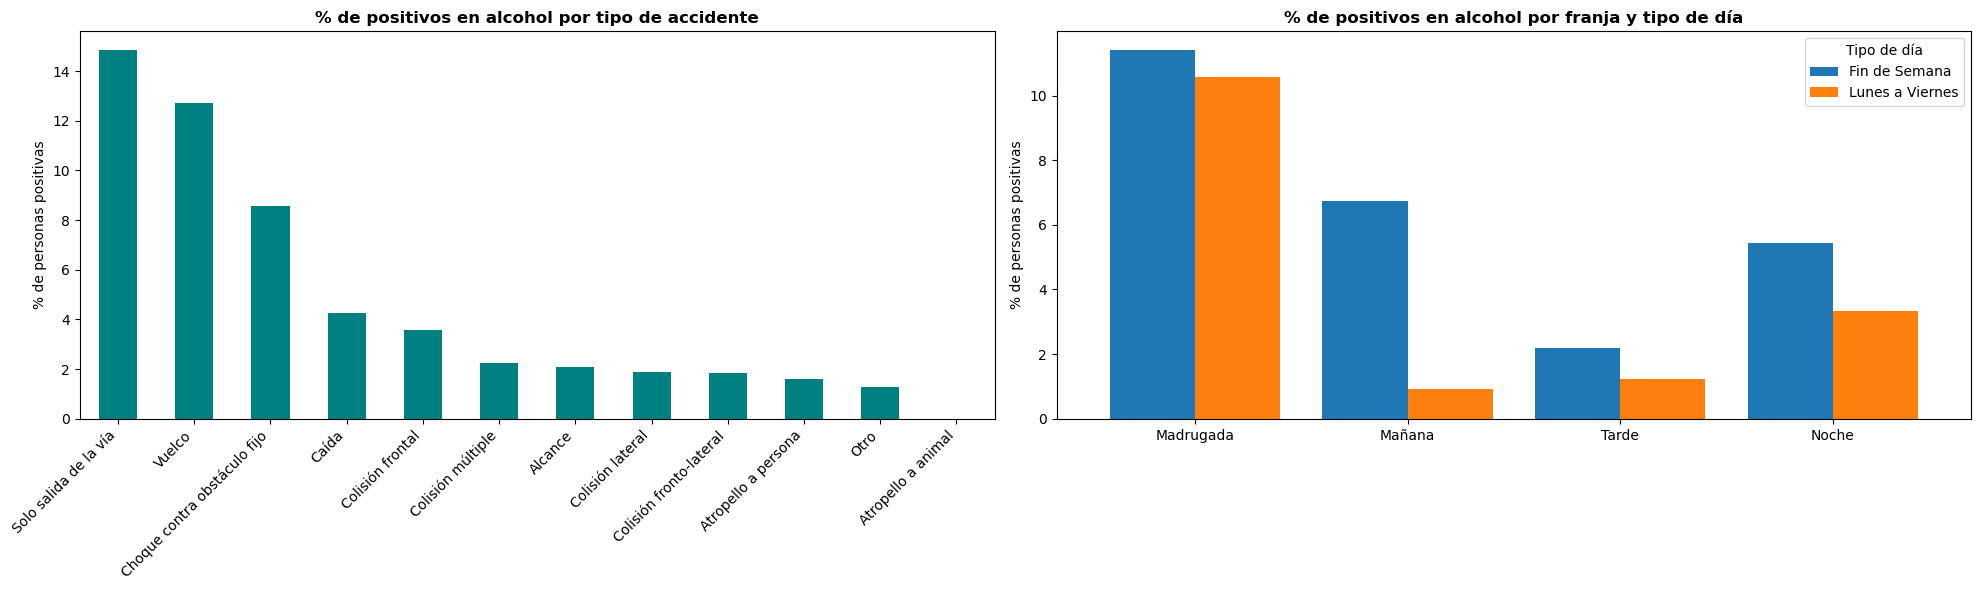

                               tasa  positivos  personas
tipo_accidente                                          
Solo salida de la vía         14.86       37.0       249
Vuelco                        12.71       23.0       181
Choque contra obstáculo fijo   8.58      455.0      5302
Caída                          4.27      114.0      2667
Colisión frontal               3.58       39.0      1088
Colisión múltiple              2.26       57.0      2522
Alcance                        2.10      253.0     12053
Colisión lateral               1.89      151.0      7989
Colisión fronto-lateral        1.85      245.0     13212
Atropello a persona            1.62       49.0      3033
Otro                           1.26       10.0       791
Atropello a animal             0.00        0.0        76

                            tasa  positivos  personas
tipo_dia        franja                               
Fin de Semana   Madrugada  11.42      266.0      2330
                Mañana      6.75      1

In [10]:
# Alcohol: ¿en qué tipos de accidente y franjas hay más positivos? (nivel PERSONA, solo con prueba registrada)

df_alc = df.dropna(subset=["positiva_alcohol"])

por_tipo = (
    df_alc.groupby("tipo_accidente")["positiva_alcohol"]
    .agg(tasa="mean", positivos="sum", personas="size")
    .sort_values("tasa", ascending=False)
)
por_franja = df_alc.groupby(["tipo_dia", "franja"], observed=True)[
    "positiva_alcohol"
].agg(tasa="mean", positivos="sum", personas="size")

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
(por_tipo["tasa"] * 100).plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("% de positivos en alcohol por tipo de accidente", fontweight="bold")
axes[0].set_ylabel("% de personas positivas")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)
for lab in axes[0].get_xticklabels():
    lab.set_ha("right")

(por_franja["tasa"] * 100).unstack("tipo_dia").reindex(orden_franja).plot(
    kind="bar", ax=axes[1], width=0.8
)
axes[1].set_title(
    "% de positivos en alcohol por franja y tipo de día", fontweight="bold"
)
axes[1].set_ylabel("% de personas positivas")
axes[1].set_xlabel("")
axes[1].legend(title="Tipo de día")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(por_tipo.assign(tasa=lambda d: (d["tasa"] * 100).round(2)).to_string())
print()
print(por_franja.assign(tasa=lambda d: (d["tasa"] * 100).round(2)).to_string())

#### Alcohol por tipo de accidente y franja (nivel persona)

La media global de positivos es el 2,91 %.

- **Tipo de accidente:** los positivos se concentran en los accidentes en los que el vehículo se queda solo: **salida de la vía (14,9 %), vuelco (12,7 %) y choque contra obstáculo fijo (8,6 %)**. Las colisiones fronto-laterales (1,85 %) o los alcances (2,10 %) están por debajo de la media, de modo que no es cierto, como se afirmaba antes, que el alcohol esté ligado a las colisiones fronto-laterales.
- **Franja horaria:** la **madrugada** tiene una positividad muy superior en cualquier tipo de día (**11,4 % en fin de semana y 10,6 % de lunes a viernes**) y, en fin de semana, se mantiene alta por la mañana (6,75 %, las horas posteriores a la noche). En cambio, la tarde de diario apenas llega al 1,2 % y la mañana de diario al 0,9 %. El factor que marca el alcohol es la hora (madrugada), no tanto que sea fin de semana.

### Categoría Adicional: Mapa de Calor y Análisis geográfico

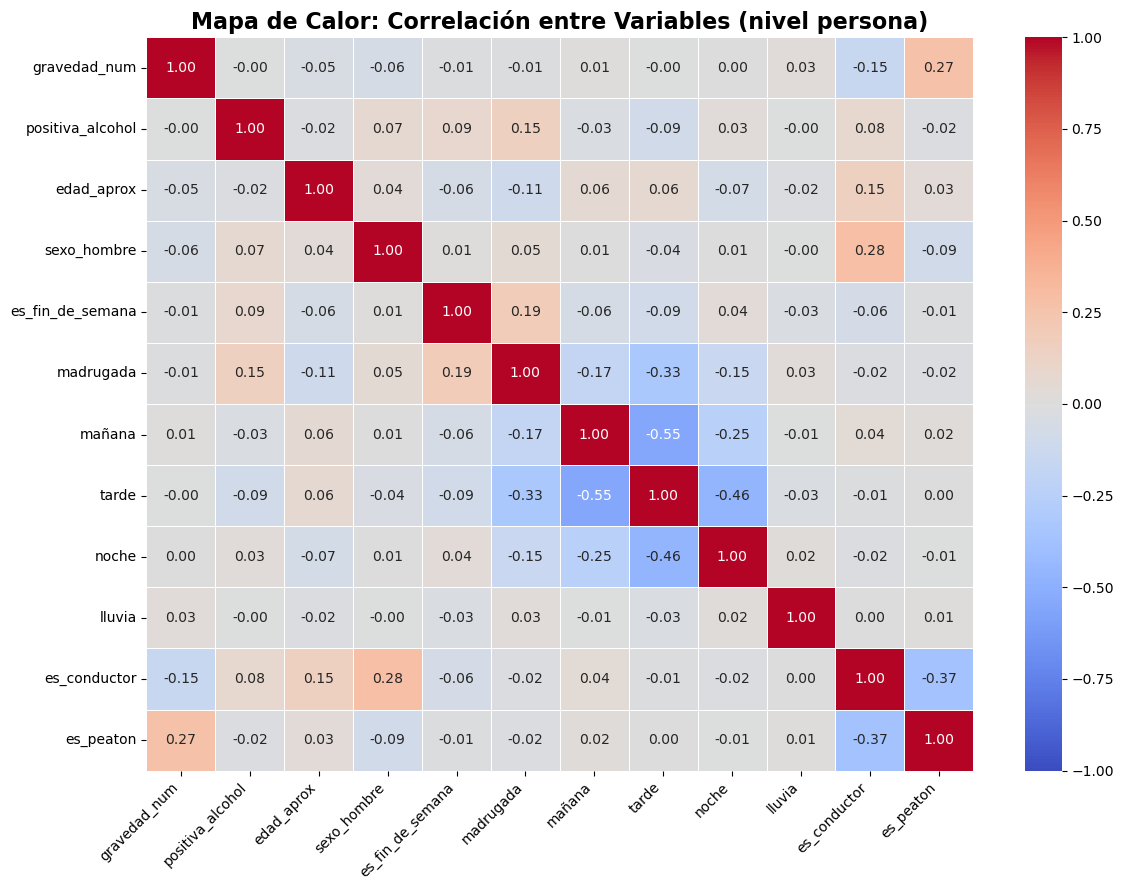

                  positiva_alcohol  gravedad_num
edad_aprox                  -0.019        -0.046
sexo_hombre                  0.066        -0.061
es_fin_de_semana             0.086        -0.010
madrugada                    0.155        -0.015
mañana                      -0.026         0.010
tarde                       -0.089        -0.003
noche                        0.028         0.004
lluvia                      -0.003         0.028
es_conductor                 0.076        -0.153
es_peaton                   -0.016         0.266


In [11]:
# Mapa de calor

# Variables numéricas o binarias (0/1) construidas SIN usar el alcohol: así las correlaciones no están predeterminadas
mapa_edad = {
    "Menor de 5 años": 2,
    "De 6 a 9 años": 7.5,
    "De 10 a 14 años": 12,
    "De 15 a 17 años": 16,
    "De 18 a 20 años": 19,
    "De 21 a 24 años": 22.5,
    "De 25 a 29 años": 27,
    "De 30 a 34 años": 32,
    "De 35 a 39 años": 37,
    "De 40 a 44 años": 42,
    "De 45 a 49 años": 47,
    "De 50 a 54 años": 52,
    "De 55 a 59 años": 57,
    "De 60 a 64 años": 62,
    "De 65 a 69 años": 67,
    "De 70 a 74 años": 72,
    "Más de 74 años": 80,
}  # 'Desconocido' -> NaN

df_corr = pd.DataFrame(
    {
        "gravedad_num": df["gravedad_num"],
        "positiva_alcohol": df["positiva_alcohol"],
        "edad_aprox": df["rango_edad"].map(mapa_edad),
        "sexo_hombre": df["sexo"].map(
            {"Hombre": 1, "Mujer": 0}
        ),  # 'Desconocido' -> NaN
        "es_fin_de_semana": (df["tipo_dia"] == "Fin de Semana").astype(int),
        "madrugada": (df["franja"] == "Madrugada").astype(int),
        "mañana": (df["franja"] == "Mañana").astype(int),
        "tarde": (df["franja"] == "Tarde").astype(int),
        "noche": (df["franja"] == "Noche").astype(int),
        "lluvia": df["estado_meteorológico"]
        .isin(["Lluvia débil", "Lluvia intensa"])
        .astype(int),
        "es_conductor": (df["tipo_persona"] == "Conductor").astype(int),
        "es_peaton": (df["tipo_persona"] == "Peatón").astype(int),
    }
)

# Calculamos la matriz de correlación
matriz_corr = df_corr.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)

plt.title(
    "Mapa de Calor: Correlación entre Variables (nivel persona)",
    fontsize=16,
    fontweight="bold",
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

# Correlaciones más relevantes con el alcohol y con la gravedad
print(
    matriz_corr[["positiva_alcohol", "gravedad_num"]]
    .drop(["positiva_alcohol", "gravedad_num"])
    .round(3)
    .to_string()
)

#### Resolución mapa de calor

Este mapa se ha recalculado con variables que **no se construyen a partir del alcohol** (edad aproximada en años, sexo, fin de semana, franjas, lluvia, tipo de persona...), de modo que las correlaciones ya no vienen predeterminadas. Los valores van de -1 a 1: 0 significa que no hay relación lineal, 1 correlación directa y -1 inversa. Como las variables son casi todas binarias y la gravedad y el alcohol son sucesos poco frecuentes, las correlaciones son modestas y hay que leerlas como indicios.

- **Gravedad:** su relación más clara es con el **peatón (+0,27)**: los peatones son la persona más vulnerable (el 11 % sufre lesiones graves frente al 0,9 % de los conductores). El ser conductor tiene el signo opuesto (-0,15). El clima (+0,03), la franja o el fin de semana apenas aportan (cercanas a 0). La gravedad con dar positivo en alcohol es -0,00: **el alcohol no se asocia linealmente con lesiones más graves en estos datos**.
- **Alcohol:** la correlación más alta es con la **madrugada (+0,15)**, seguida de fin de semana (+0,09), ser conductor (+0,08), hombre (+0,07) y negativa con la tarde (-0,09).
- **Entre variables:** se confirma que ser conductor y ser hombre van juntos (+0,28), así como madrugada y fin de semana (+0,19). Las correlaciones entre las franjas son negativas por construcción (si es de tarde no puede ser de madrugada). La relación edad-sexo (0,04) no es relevante: el "0,34" del análisis anterior era un artefacto de la codificación por tasa de alcohol.

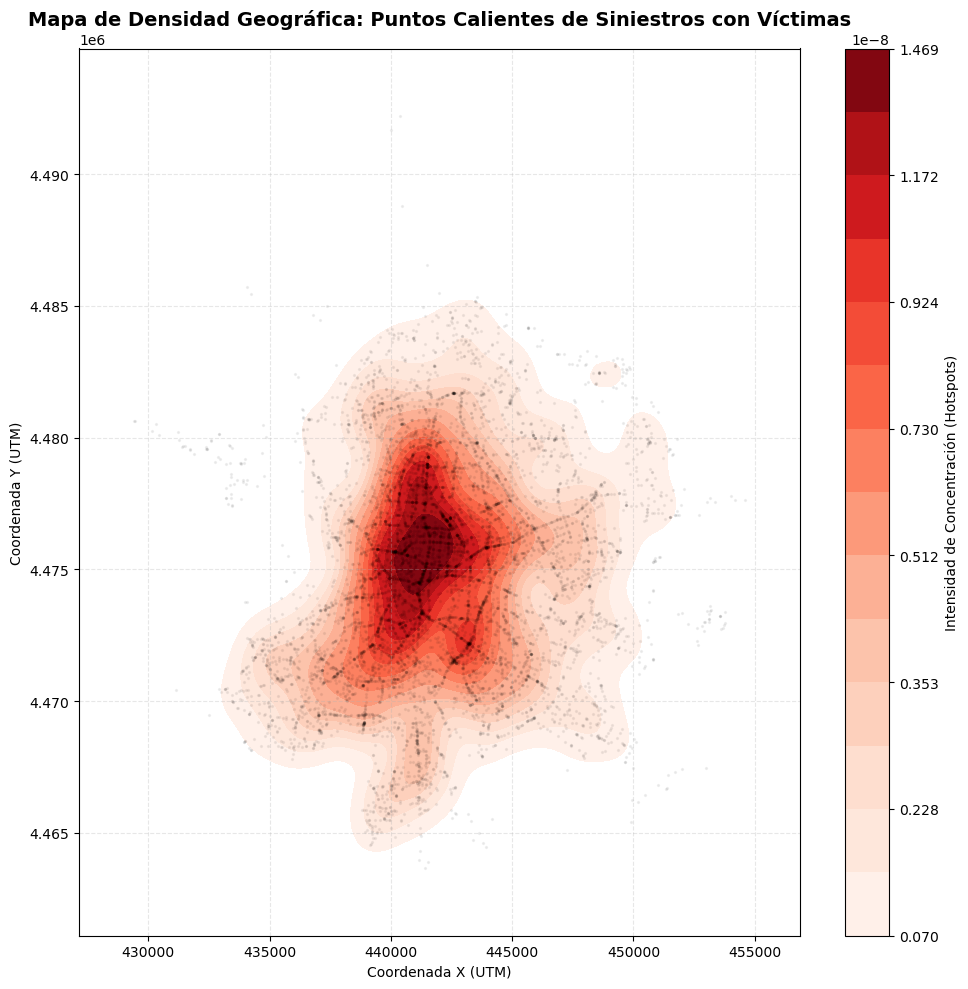

Accidentes representados en el mapa: 9051


In [12]:
# Análisis geográfico (nivel ACCIDENTE: cada punto es un siniestro, no una persona)

# Filtramos accidentes con víctimas (heridos o fallecidos) y limpiamos coordenadas irreales (0 o nulas)
df_geo = df_acc[
    (df_acc["gravedad_max"] > 0)
    & (df_acc["coordenada_x_utm"] > 0)
    & (df_acc["coordenada_y_utm"] > 0)
].dropna(subset=["coordenada_x_utm", "coordenada_y_utm"])

plt.figure(figsize=(10, 10))

# Dibujamos el mapa de densidad KDE
sns.kdeplot(
    data=df_geo,
    x="coordenada_x_utm",
    y="coordenada_y_utm",
    fill=True,
    thresh=0.05,
    levels=15,
    cmap="Reds",
    cbar=True,
    cbar_kws={"label": "Intensidad de Concentración (Hotspots)"},
)

# Dibujamos los accidentes reales encima con puntos negros
plt.scatter(
    df_geo["coordenada_x_utm"],
    df_geo["coordenada_y_utm"],
    color="black",
    alpha=0.05,
    s=2,
    label="Siniestros individuales",
)

plt.title(
    "Mapa de Densidad Geográfica: Puntos Calientes de Siniestros con Víctimas",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Coordenada X (UTM)")
plt.ylabel("Coordenada Y (UTM)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Accidentes representados en el mapa: {len(df_geo)}")

#### Resolución de la gráfica
El análisis geográfico mediante estimación de densidad de kernel (KDE) se calcula ahora con **un punto por accidente** (9.051 siniestros con heridos o fallecidos), de modo que los accidentes con muchas víctimas no pesan más que el resto. Permite identificar de forma visual y matemática los "puntos calientes" (*hotspots*) de la siniestralidad con víctimas en Madrid. Las zonas sombreadas en rojo intenso representan áreas críticas de alta concentración de accidentes con heridos o fallecidos. Y las zonas rojo-blancas son posiciones donde apenas ocurren incidentes, que como se puede apreciar es a las afueras de Madrid.

Estos núcleos geográficos no se distribuyen de manera uniforme, sino que se agrupan firmemente en torno a los principales nodos de comunicación de la capital, grandes intersecciones y, de manera muy destacada, en los ejes e incorporaciones de vías de alta capacidad como la M-30.


### Limitaciones del dataset

Según mi punto de vista hay algunas limitaciones como:

•	**Granularidad mixta:** el dataset mezcla información del accidente y de cada persona implicada. Es imprescindible agrupar por `num_expediente` para contar siniestros, y aun así no sabemos si todas las personas de un accidente están registradas. La relación entre personas del mismo accidente también rompe la independencia de las filas en el modelo.

•	Ausencia de contexto de volumen de tráfico: Sabemos que hay más accidentes los viernes por la tarde, pero no tenemos el dato de cuántos coches circulaban en total. Contar con el aforo de vehículos (intensidad media diaria) permitiría calcular tasas reales de accidentalidad en lugar de solo volúmenes absolutos.

•	Datos geográficos incompletos o ruidosos: Durante el análisis, se detectaron registros con coordenadas UTM nulas o con valor 0, lo que obligó a filtrar el dataset. Mejorar la captura de datos GPS por parte de los agentes en el lugar del siniestro enriquecería el mapa de densidad.

•	Falta de datos de velocidad: No disponemos de la velocidad a la que circulaba el vehículo ni del límite de la vía. Incluir esta variable explicaría de forma mucho más precisa la lesividad del accidente.

•	Categorías genéricas y datos que faltan: En variables como el clima, la categoría "Desconocido" o "Se ignora" agrupa a veces demasiados registros (13 % de los accidentes), restando precisión al análisis meteorológico. Además, el sexo y la edad desconocidos (≈ 11 % de las personas) no son aleatorios: las 5.230 personas de sexo desconocido tienen 0 positivos en alcohol, y casi todas son conductores, lo que sugiere que son vehículos que no se identificaron (por ejemplo, una huida), no personas a las que se hizo la prueba y dio negativo.

•	Sucesos poco frecuentes: solo el 2,9 % de las personas da positivo en alcohol y el 2,7 % de los accidentes es grave. Con tan pocos casos, las tasas de subgrupos pequeños (fin de semana, granizo, nieve...) son muy inestables.

### Conclusiones del EDA y Preguntas A Resolver

Todas las cifras de este apartado cuentan **accidentes** (20.692) o indican explícitamente que son **personas**.

1.	**¿Existe relación entre el estado meteorológico y la lesividad?**
No hay evidencia de que la lluvia agrave los accidentes: el 3,12 % de los accidentes en tiempo despejado es grave frente al 2,07 % (lluvia débil) y el 1,81 % (lluvia intensa); la diferencia no es significativa (p = 0,16). Granizo y nieve (3 accidentes en total) no permiten concluir nada.

2.	**¿En qué tipos de accidente se da más frecuencia de positivos en alcohol?**
En los accidentes en que el vehículo se queda solo: **salida de la vía (14,9 %), vuelco (12,7 %) y choque contra obstáculo fijo (8,6 %)**, frente al 2,9 % de media. Las colisiones fronto-laterales (1,85 %) están por debajo de la media.

3.	**¿Los accidentes de madrugada tienen mayor positividad en alcohol?**
Afirmativo: dan positivo el 11,4 % de las personas en madrugada de fin de semana y el 10,6 % en la de diario, cuatro veces la media. Además, la madrugada de fin de semana tiene 2,40 veces más accidentes por día natural que la de un día laborable (+140 %).

4.	**¿Existen diferencias demográficas vinculadas a los siniestros?**
Sí, aunque con matices. Entre las personas con prueba registrada, los hombres dan positivo con más frecuencia que las mujeres (4,1 % frente a 1,6 %) y los conductores mucho más que los pasajeros (3,6 % frente a 0,1 %). En gravedad, el peatón es el perfil más vulnerable (11 % sufre lesiones graves frente al 0,9 % de los conductores).

5.	**Geografía y Puntos Calientes:**
El análisis con estimación de densidad (KDE), con un punto por accidente, reveló que los accidentes con víctimas no se distribuyen por igual en los distritos, sino que se centralizan en el interior de la M-30 y en las principales autovías radiales de entrada/salida.

6.	**Hora del día y tipología (Pregunta de negocio):**
La tarde de lunes a viernes domina en volumen (31,3 accidentes por día natural), con alcances y colisiones fronto-laterales prácticamente empatados. Sin embargo, en **proporción de accidentes graves la tarde es la franja menos grave (2,24 %)** y la más grave es la **madrugada (3,54 %)**.

### Respuesta a la Pregunta de Negocio

**Pregunta:** *“¿En qué franja horaria se producen los accidentes con mayor gravedad (ingreso superior a 24 horas o fallecidos) y qué condiciones (estado meteorológico, tipo de accidente, etc.) pueden influir en ello?”*

**Respuesta y Hallazgos** (unidad de análisis: accidente, 20.692 en total):

La franja con **mayor gravedad es la madrugada**: el **3,54 %** de sus accidentes es grave (70 de 1.975), frente al 3,10 % de la noche, el 2,91 % de la mañana y el 2,24 % de la tarde. Las diferencias son significativas (p < 0,001). El valor máximo se da en la madrugada de fin de semana (4,15 %). La tarde acumula más accidentes graves en número absoluto (230) porque es la franja con más tráfico, pero es la menos grave en proporción: **gravedad y volumen no coinciden**. Esta respuesta corrige la versión anterior (tarde-noche de fin de semana, "+250 %"), que se apoyaba en conteos de personas y no de accidentes.

Condiciones que influyen:

1. **Tipo de Accidente:** es el factor que más discrimina. El **atropello a persona** es grave en el 12,5 % de los casos (frente al 2,67 % global), seguido de vuelco (4,7 %) y caída (4,3 %); las colisiones entre vehículos (alcance, lateral) y el choque contra obstáculo fijo rara vez superan el 1,2 %. Los peatones son además el perfil con más correlación con la gravedad (+0,27).

2. **Estado Meteorológico:** no se observa que la lluvia incremente la proporción de accidentes graves (2,07 % con lluvia débil y 1,81 % con intensa, frente al 3,12 % con tiempo despejado; no significativo). Probablemente se circule más despacio con lluvia. Granizo y nieve (3 accidentes) no permiten concluir nada.

3. **Factor Humano (alcohol):** la positividad en alcohol se concentra en la madrugada (11,4 % en fin de semana, 10,6 % de diario, frente al 2,9 % global) y en los accidentes de salida de vía, vuelco y choque contra obstáculo. Es coherente con que la madrugada sea la franja más grave, pero **en los datos no existe una relación lineal directa entre dar positivo y la gravedad** (correlación -0,00), por lo que el alcohol explica *cuándo* ocurren los accidentes más que *cuán graves* son. No se ha comprobado qué parte de la mayor gravedad nocturna se debe al tipo de accidente o a la velocidad (variable que no tenemos).

## Parte 2: Análisis de Datos y entrenamiento de modelo

#### Planteamiento del modelo

Se entrena una **regresión logística** que predice si una **persona implicada** dio positivo en alcohol. El modelo se mantiene a nivel persona (una fila = una persona), no a nivel accidente, porque el objetivo es individual.

Cambios respecto a la versión anterior:

- **Sin fuga de datos:** las predictoras (franja, tipo de accidente, edad, sexo, vehículo) se codifican en columnas binarias (one-hot). Antes se sustituía cada categoría por su tasa de alcohol, calculada con todo el dataset (incluido el test), de modo que el modelo recibía información del objetivo y las métricas salían optimistas.
- Las filas sin resultado de la prueba (167) no se pueden usar para entrenar ni evaluar y se excluyen.
- Se mantiene la división 80/20 estratificada (necesaria por el fuerte desbalanceo) y `class_weight='balanced'`.
- La evaluación devuelve ahora accuracy, precision, recall, F1 y la matriz de confusión.

In [13]:
from models import AlcoholLogisticModel  # mi clase
from sklearn.model_selection import train_test_split

print("1. PREPARACIÓN DE DATOS (nivel PERSONA: se predice el positivo individual)")

# El objetivo es conocido solo en quien tiene prueba registrada
df_modelo = df.dropna(subset=["positiva_alcohol"])

features = ["franja", "tipo_accidente", "rango_edad", "sexo", "grupo_vehiculo"]
y = df_modelo["positiva_alcohol"].astype(int)

# Codificación binaria (one-hot): una columna 0/1 por categoría. No usa 'y' en ningún momento -> no hay fuga de datos
X = pd.get_dummies(df_modelo[features].astype(str), dtype=int)
print(
    f"Variables predictoras: {X.shape[1]} columnas binarias a partir de {len(features)} variables"
)

# Separacion de datos 20% test

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Datos de entrenamiento: {X_train.shape[0]} filas.")
print(f"Datos de test: {X_test.shape[0]} filas.")
print(
    f"% de positivos -> train: {y_train.mean() * 100:.2f}% | test: {y_test.mean() * 100:.2f}%\n"
)

# Entrenamiento del modelo

print("2. ENTRENAMIENTO Y EVALUACIÓN")

modelo_alcohol = AlcoholLogisticModel(
    max_iter=1000
)  # le doy mas tiempo al modelo para entrenar

modelo_alcohol.fit(X_train, y_train)
metricas = modelo_alcohol.evaluate(X_test, y_test)
modelo_alcohol.save_model("modelo_regresion_alcohol.pkl")

print("\nMétricas en test (clase positiva = alcohol):")
for nombre in ["accuracy", "precision", "recall", "f1"]:
    print(f"  {nombre:10s}: {metricas[nombre]:.3f}")
print(
    f"  (referencia: un modelo 'vago' que siempre dice 'sobrio' tendría accuracy {1 - y_test.mean():.3f} y recall 0)"
)

1. PREPARACIÓN DE DATOS (nivel PERSONA: se predice el positivo individual)
Variables predictoras: 46 columnas binarias a partir de 5 variables
Datos de entrenamiento: 39330 filas.
Datos de test: 9833 filas.
% de positivos -> train: 2.91% | test: 2.92%

2. ENTRENAMIENTO Y EVALUACIÓN
Modelo entrenado correctamente
Modelo evaluado
Modelo guardado en: modelo_regresion_alcohol.pkl

Métricas en test (clase positiva = alcohol):
  accuracy  : 0.800
  precision : 0.099
  recall    : 0.718
  f1        : 0.173
  (referencia: un modelo 'vago' que siempre dice 'sobrio' tendría accuracy 0.971 y recall 0)


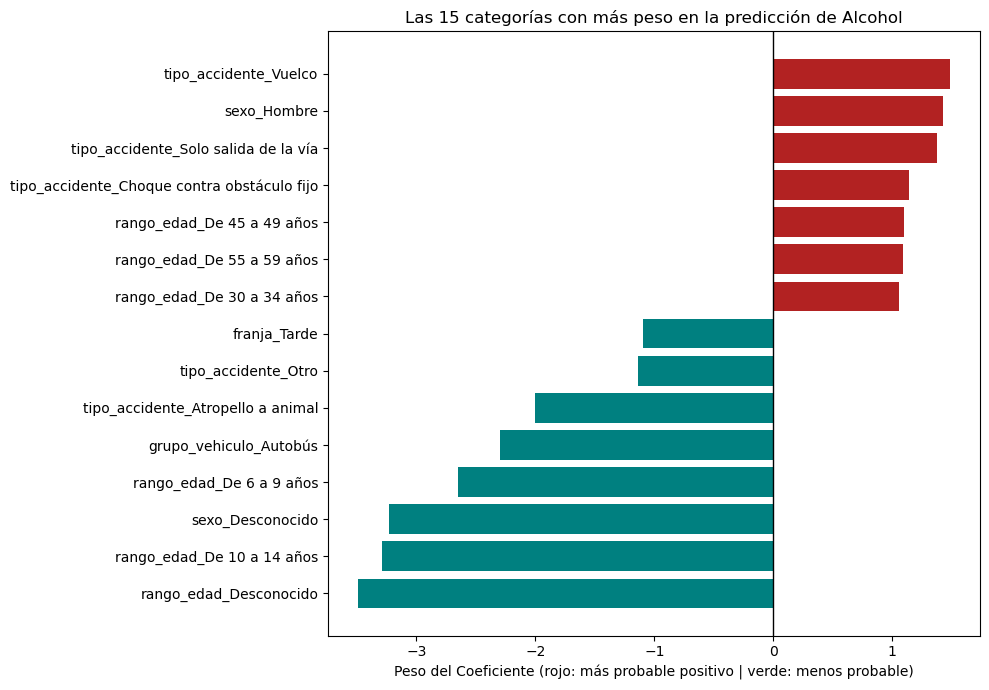

                                   Variable  Coeficiente
                      tipo_accidente_Vuelco        1.487
                                sexo_Hombre        1.424
       tipo_accidente_Solo salida de la vía        1.375
tipo_accidente_Choque contra obstáculo fijo        1.140
                 rango_edad_De 45 a 49 años        1.102
                 rango_edad_De 55 a 59 años        1.090
                 rango_edad_De 30 a 34 años        1.055
                               franja_Tarde       -1.095
                        tipo_accidente_Otro       -1.139
          tipo_accidente_Atropello a animal       -2.001
                     grupo_vehiculo_Autobús       -2.293
                   rango_edad_De 6 a 9 años       -2.646
                           sexo_Desconocido       -3.232
                 rango_edad_De 10 a 14 años       -3.291
                     rango_edad_Desconocido       -3.492


In [14]:
# Resultados: coeficientes del modelo
# Cada coeficiente es el peso de UNA categoría (columna 0/1); positivo = aumenta la probabilidad de dar positivo en alcohol.

importancia = pd.DataFrame(
    {"Variable": X.columns, "Coeficiente": modelo_alcohol.model.coef_[0]}
)

importancia["Abs_Coef"] = importancia[
    "Coeficiente"
].abs()  # Ordena por valores absolutos, excluyendo los signos negativos
importancia = (
    importancia.sort_values(by="Abs_Coef", ascending=False)
    .head(15)
    .sort_values("Coeficiente")
)

plt.figure(figsize=(10, 7))
plt.barh(
    importancia["Variable"],
    importancia["Coeficiente"],
    color=np.where(importancia["Coeficiente"] > 0, "firebrick", "teal"),
)
plt.title("Las 15 categorías con más peso en la predicción de Alcohol")
plt.xlabel("Peso del Coeficiente (rojo: más probable positivo | verde: menos probable)")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

print(
    importancia.sort_values("Coeficiente", ascending=False)[["Variable", "Coeficiente"]]
    .round(3)
    .to_string(index=False)
)

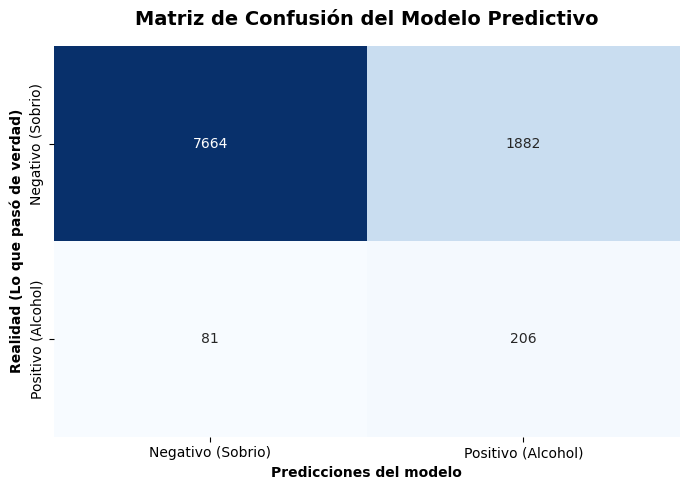

Sobrios bien clasificados (TN): 7664 | Falsas alarmas (FP): 1882 | Positivos que se escapan (FN): 81 | Positivos detectados (TP): 206


In [15]:
# Quise mostrar cual fue la tasa de verdaderos aciertos y falsos aciertos porque lo considere importante

cm = metricas["confusion_matrix"]

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Negativo (Sobrio)", "Positivo (Alcohol)"],
    yticklabels=["Negativo (Sobrio)", "Positivo (Alcohol)"],
)

plt.title(
    "Matriz de Confusión del Modelo Predictivo", fontsize=14, fontweight="bold", pad=15
)
plt.ylabel("Realidad (Lo que pasó de verdad)", fontweight="bold")
plt.xlabel("Predicciones del modelo", fontweight="bold")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(
    f"Sobrios bien clasificados (TN): {tn} | Falsas alarmas (FP): {fp} | Positivos que se escapan (FN): {fn} | Positivos detectados (TP): {tp}"
)

**Lectura de la matriz de confusión (conjunto de test: 9.833 personas, 287 positivas):**

- Se detectan **206 de los 287 positivos** (*recall* del 71,8 %) y se escapan 81.
- Se clasifican bien 7.664 personas sobrias, pero se señalan por error 1.882 (falsas alarmas). Por eso la *precisión* es solo del **9,9 %**: de cada 10 personas que el modelo marca como positivas, solo 1 lo es de verdad (F1 = 0,17).
- La *accuracy* es del 80,0 %. Un modelo "vago" que dijera siempre "sobrio" tendría un 97,1 %, pero detectaría 0 positivos; por eso la exactitud sola es engañosa con este desbalanceo y hay que mirar recall y precisión.

Estas métricas son las honestas: son menos llamativas que las de la versión anterior porque ya no incluyen información del objetivo.

### Conclusiones del Modelo Predictivo y Pregunta de Negocio

Para terminar el proyecto, se ha creado un modelo que ha estudiado a las personas implicadas en los accidentes para responder a una pregunta: ¿Cuáles son las mayores pistas de que alguien ha bebido?

1. En Madrid, la inmensa mayoría de la gente conduce sobria (solo el 2,9 % da positivo). Si nuestro programa fuera "vago", simplemente diría siempre "nadie ha bebido" y acertaría casi siempre (97 %) sin detectar a nadie. Para evitar que hiciera esa trampa, le obligamos a prestarle muchísima más atención a los positivos, aunque fueran pocos.
**¿El resultado?** El programa acierta el 80 % de las veces en general y es capaz de detectar a **7 de cada 10 positivos** (recall del 72 %), pero a costa de muchas falsas alarmas: solo 1 de cada 10 personas señaladas es positiva. Sirve como filtro para priorizar controles, no como prueba definitiva.

2. ¿En qué pistas se fija el programa para acertar?
Las categorías con mayor peso (ver gráfico de coeficientes) son:
•	**El tipo de accidente:** vuelco, salida de la vía y choque contra obstáculo fijo aumentan mucho la probabilidad de positivo, algo que ya se vio en el análisis exploratorio.
•	**Sexo y edad:** ser hombre y tener entre 30 y 59 años aumenta la probabilidad. Los pesos más negativos corresponden a las categorías con datos que faltan (sexo o edad desconocidos: ninguna de esas personas tiene un positivo, lo que sugiere vehículos no identificados) y a los menores (6 a 14 años) y los autobuses, que lógicamente casi no dan positivo.
•	**La hora del día:** la tarde reduce la probabilidad (peso negativo), en línea con el 1,2 % de positividad que se vio en la tarde de diario.
Antes se concluía que "la edad es lo que más mira el modelo", pero era un artefacto: la "edad" de entonces era la tasa de alcohol de cada tramo, no la edad. Con la codificación binaria cada coeficiente se puede interpretar como el efecto de esa categoría concreta.

3. Limitaciones del modelo: se han usado solo 5 variables de contexto del accidente y de la persona (no hay datos de velocidad, tipo de vía ni de la conducta del conductor), la clase positiva es muy minoritaria y varias personas del mismo accidente están a la vez en entrenamiento y en test (comparten tipo de accidente y franja). Una mejora futura sería separar entrenamiento y test por accidente completo y validar con validación cruzada.

### Prueba del test

In [16]:
from test_models import ejecutar_test

ejecutar_test()

--- INICIANDO TEST DE LA CLASE AlcoholLogisticModel ---

1. Generando datos falsos para la prueba...
Datos generados correctamente.

2. Creando el modelo (instanciando la clase)...

3. Probando la función fit()...
Modelo entrenado correctamente

4. Probando la función evaluate()...
Modelo evaluado
Metricas devueltas: {'accuracy': 0.89, 'precision': 0.394, 'recall': 0.867, 'f1': 0.542}

5. Probando guardar y cargar en disco...
Modelo guardado en: modelo_prueba_temporal.pkl
Modelo cargado desde: modelo_prueba_temporal.pkl
El modelo cargado produce las mismas predicciones que el original.
Archivo temporal de prueba borrado con éxito.

Test finalizado correctamente
